# Notebook 06 — VaR Backtesting

Estimating Value at Risk is only the first step. A risk model should also be tested to determine whether its predictions are consistent with actual market outcomes.

In this notebook, Historical VaR is recalculated each day using a rolling one-year estimation window and compared with the realised portfolio returns. The Kupiec Proportion of Failures (POF) test is then applied to evaluate whether the observed number of VaR breaches is statistically consistent with the model's confidence level.

This provides an objective way to assess the reliability of the risk model.

## Outputs

- Rolling Historical VaR
- VaR breach analysis
- Kupiec LR statistic
- p-value and model validation


Backtesting Results
--------------------------------------------------------------------
Level       Expected    Observed     LR Stat     p-value    Result
--------------------------------------------------------------------
95%       113.3         106      0.4988      0.4800      PASS
99%        22.7          32      3.4559      0.0630      PASS
--------------------------------------------------------------------
Model passes if p-value > 0.05.


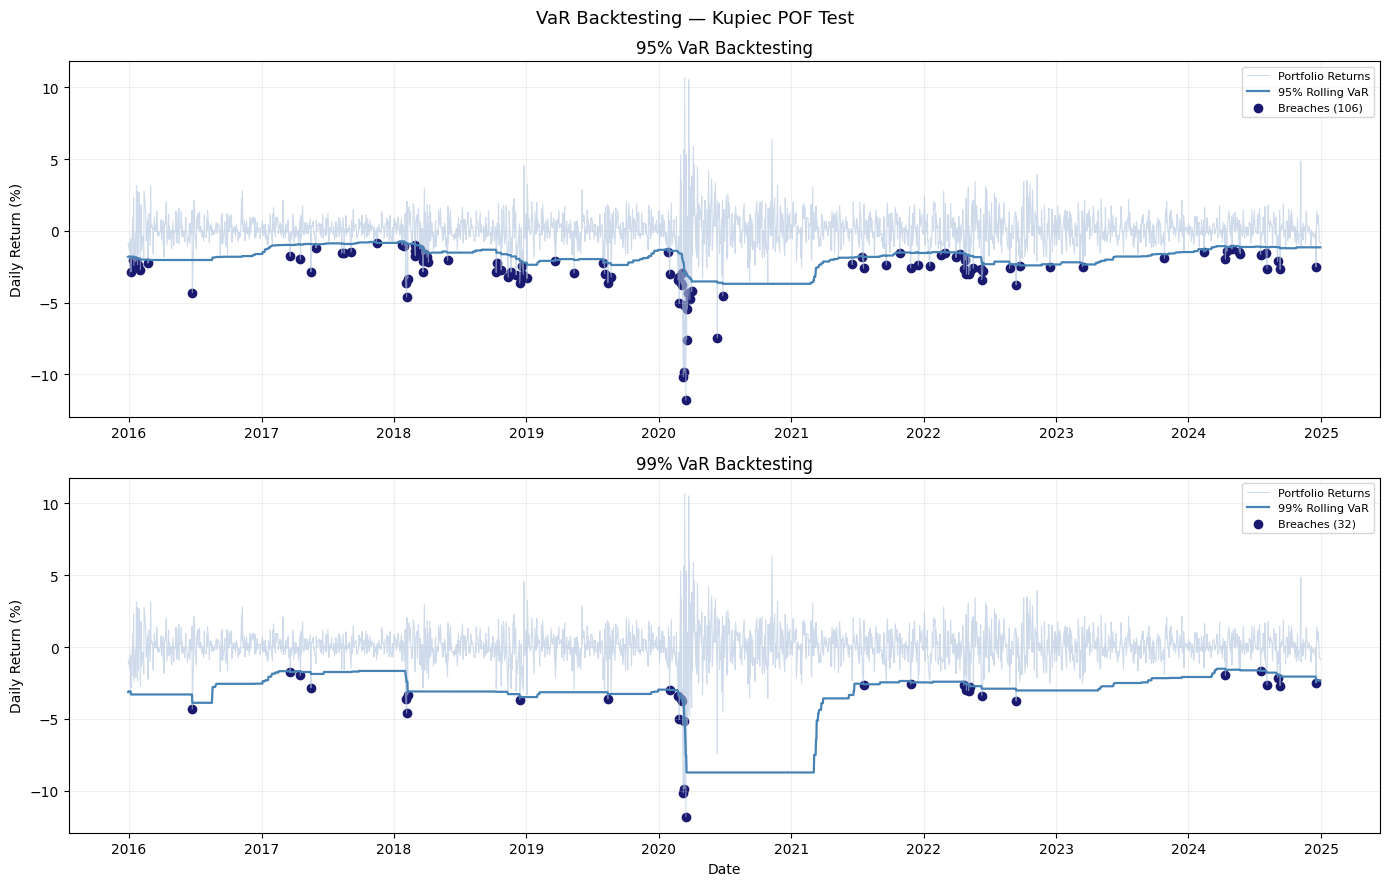

In [1]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2

pd.set_option('display.float_format', '{:.4f}'.format)

# Configuration

weights           = np.array([0.20, 0.20, 0.20, 0.20, 0.20])
confidence_levels = [0.95, 0.99]

# Load Data

log_returns = pd.read_csv(  '../data/log_returns.csv', index_col=0, parse_dates=True)

portfolio_returns = log_returns.dot(weights)

# Compute Rolling Historical VaR

rolling_window = 250

def rolling_var(returns, window, confidence):
    return returns.rolling(window).apply(lambda x: -np.percentile(x, (1 - confidence) * 100),raw=True)

# Kupiec Proportion of Failures (POF) Test

def kupiec_test(n_obs, n_breaches, confidence):
    """
    Kupiec Proportion of Failures (POF) Test

    H0 : Observed breach rate equals expected breach rate.

    Returns:
        LR statistic
        p-value
        Pass / Fail
    """

    p = 1 - confidence
    p_hat = n_breaches / n_obs

    if p_hat == 0 or p_hat == 1:
        return np.nan, np.nan, False

    lr = -2 * ( n_breaches * np.log(p / p_hat)+ (n_obs - n_breaches) * np.log((1 - p) / (1 - p_hat)) )

    p_value = 1 - chi2.cdf(lr, df=1)

    passed = p_value > 0.05

    return lr, p_value, passed


print("\nBacktesting Results")
print("-" * 68)
print(f"{'Level':<8}{'Expected':>12}{'Observed':>12}{'LR Stat':>12}{'p-value':>12}{'Result':>10}")
print("-" * 68)

breach_series = {}

for cl in confidence_levels:

    var_series = rolling_var(portfolio_returns, rolling_window, cl)

    valid = var_series.dropna()

    aligned = portfolio_returns.loc[valid.index]

    breaches = (aligned < -valid).astype(int)

    n_valid = len(valid)

    n_breaches = breaches.sum()

    expected = n_valid * (1 - cl)

    lr, p_value, passed = kupiec_test(
        n_valid,
        n_breaches,
        cl)

    breach_series[cl] = {
        "var": valid,
        "breaches": breaches,
        "n_breaches": n_breaches,
        "expected": expected}

    status = "PASS" if passed else "FAIL"

    print(
        f"{cl*100:.0f}%"
        f"{expected:>12.1f}"
        f"{n_breaches:>12}"
        f"{lr:>12.4f}"
        f"{p_value:>12.4f}"
        f"{status:>10}")

print("-" * 68)
print("Model passes if p-value > 0.05.")

#Visualization

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

fig.suptitle("VaR Backtesting — Kupiec POF Test", fontsize=13)

for idx, cl in enumerate(confidence_levels):

    ax = axes[idx]

    data = breach_series[cl]

    var_series = data["var"]

    breaches = data["breaches"]

    dates = var_series.index

# Portfolio Returns
    ax.plot(
        dates,
        portfolio_returns.loc[dates] * 100,
        color="lightsteelblue",
        linewidth=0.8,
        alpha=0.60,
        label="Portfolio Returns")

# Rolling VaR
    ax.plot(
        dates,
        -var_series * 100,
        color="steelblue",
        linewidth=1.6,
        label=f"{cl*100:.0f}% Rolling VaR")

# Breaches
    breach_dates = breaches[breaches == 1].index

    ax.scatter(
        breach_dates,
        portfolio_returns.loc[breach_dates] * 100,
        color="midnightblue",
        label=f"Breaches ({data['n_breaches']})")

    ax.set_title(f"{cl*100:.0f}% VaR Backtesting")

    ax.set_ylabel("Daily Return (%)")

    ax.legend(fontsize=8)

    ax.grid(alpha=0.2)

axes[-1].set_xlabel("Date")

plt.tight_layout()

os.makedirs("../reports", exist_ok=True)

plt.savefig("../reports/06_backtesting.png", dpi=150)

plt.show()